## Part1 Baseline Discrete Local Search (Hill‑Climber)
### Student: Beverly, Echo
### Student ID: 202316801316,202316801317

### Common utility functions
Below are shared helper functions reused by all group members:
1. `calculate_total_resource()`: compute total hardware resource consumption for a binary solution
2. `is_feasible()`: check whether a solution respects all hardware capacity bounds
3. `fitness()`: objective function with **penalty‑based constraint handling**.
If solution violates resource constraints, heavy penalty is subtracted from utility value to discourage infeasible solutions.

In [4]:
import numpy as np
import matplotlib.pyplot as plt

# ========= Shared group functions (consistent with team‑member interface) =========
def load_instance(file_path):
    
    with open(file_path, 'r') as f:
        tokens = f.read().split()

    if not tokens:
        raise ValueError(f"Dataset file at '{file_path}' is empty or invalid.")

    n = int(tokens[0])
    m = int(tokens[1])
    idx = 2

    v = np.array([float(x) for x in tokens[idx: idx + n]])
    idx += n

    W = np.zeros((m, n))
    for i in range(m):
        W[i, :] = [float(x) for x in tokens[idx: idx + n]]
        idx += n

    b = np.array([float(x) for x in tokens[idx: idx + m]])
    return n, m, v, W, b

def is_feasible(sol, W, b):
    "Check if the solution is feasible: sol is a 0/1 array"
    cons = W @ sol
    return np.all(cons <= b + 1e-9)

def evaluate_fitness(sol, v, W, b):
    "Basic fitness: Feasible solutions = total value; Infeasible = 0"
    if is_feasible(sol, W, b):
        return float(v @ sol)
    else:
        return 0.0


# ========== Variant B Core: Repair Recovery Strategy  ==========
def repair_solution(sol, W, b, v):

    sol = sol.copy().astype(int)
    n = len(sol)
    # value density
    density = np.zeros(n)
    mask = sol == 1
    density[mask] = v[mask] / (W[:,mask].sum(axis=0) + 1e-9)
    # Retrieve the index of the currently selected item, sort them in ascending order of density
    selected_idx = np.where(sol == 1)[0]
    selected_idx = selected_idx[np.argsort(density[selected_idx])]

    for idx in selected_idx:
        if is_feasible(sol, W, b):
            break
        sol[idx] = 0
    return sol


# ==================== Variant‑A Penalty‑based constraint handling (Part‑1 Hill‑Climber) ====================
def fitness_penalty(sol, v, W, b, penalty_weight=10000):
    
    total_val = np.sum(v * sol)
    if is_feasible(sol, W, b):
        return total_val
    overshoot = np.maximum((W @ sol) - b, 0.0)
    return total_val - penalty_weight * np.sum(overshoot)

### 1.1 Hill‑Climber algorithm design
1. **Solution representation**: Binary numpy vector `sol` of length n. $sol_j=1$ means deploy model $j$; $sol_j=0$ means skip model $j$.
2. **Neighbourhood / Mutation operator**: Single‑bit flip. In each iteration pick one random index and toggle value $0 \leftrightarrow 1$ to generate neighbour candidate solution.
3. **Acceptance rule (greedy hill‑climbing)**: Only accept neighbour candidate if it achieves higher penalised fitness value.
4. **Constraint‑handling**: Use **Variant‑A penalty‑function (`fitness_penalty`)**. Infeasible solutions receive heavy fitness penalty, but solution vector will not be modified.
5. **Stopping condition**: fixed maximum iteration search budget.

Known limitation: Greedy hill‑climber is prone to being trapped in local optima and lacks global exploration capacity. It works as a baseline solver for small‑scale instance n=28, but cannot handle high‑dimensional n=90 challenge problem.


In [5]:
def hill_climber(n, v, W, b, max_iter=1500, seed=42):
    rng = np.random.default_rng(seed)
    # generate random initial binary solution
    current_sol = rng.integers(0, 2, size=n)
    current_fit = fitness_penalty(current_sol, v, W, b)

    best_sol = current_sol.copy()
    best_fit = current_fit
    convergence_history = []

    for _ in range(max_iter):
        convergence_history.append(best_fit)
        # single‑bit flip neighbour operator
        neighbour = current_sol.copy()
        flip_pos = rng.integers(0, n)
        neighbour[flip_pos] = 1 - neighbour[flip_pos]

        neighbour_fit = fitness_penalty(neighbour, v, W, b)
        # greedy acceptance: accept only better fitness
        if neighbour_fit > current_fit:
            current_sol = neighbour
            current_fit = neighbour_fit
            if current_fit > best_fit:
                best_fit = current_fit
                best_sol = current_sol.copy()
    return best_sol, best_fit, convergence_history

### 1.2 Experimental setup
- Dataset file: `multi_resource_n28_m2.txt` ($n=28$, $m=2$)
- Number of independent repeated runs: 10
- Max iterations for each single run: 1500
- Reproducibility: Each independent run uses distinct fixed random seed.

We collect final best fitness value from every run for statistical summary, and store full convergence history to plot convergence curve.

==== Hill‑Climber Results | Instance n=28 m=2 ====
Independent runs: 10
Iteration budget per run: 1500
Maximum fitness: 95205.00
Minimum fitness: 39012.00
Mean fitness:    73649.90
Std deviation:  16970.18


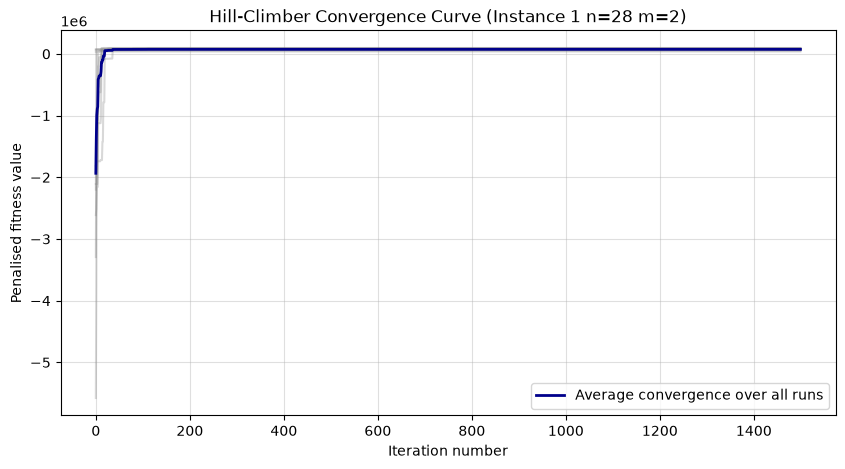

In [12]:
# load dataset
n, m, v, W, b = load_instance(r"D:/大四上/AI/数据/multi_resource_n28_m2 .txt")

num_runs = 10
max_iter = 1500

all_best_fitness = []
all_convergence_histories = []

for run_id in range(num_runs):
    best_s, best_fit, hist = hill_climber(n, v, W, b, max_iter=max_iter, seed=run_id)
    all_best_fitness.append(best_fit)
    all_convergence_histories.append(hist)

# print statistical summary
print("==== Hill‑Climber Results | Instance n=28 m=2 ====")
print(f"Independent runs: {num_runs}")
print(f"Iteration budget per run: {max_iter}")
print(f"Maximum fitness: {np.max(all_best_fitness):.2f}")
print(f"Minimum fitness: {np.min(all_best_fitness):.2f}")
print(f"Mean fitness:    {np.mean(all_best_fitness):.2f}")
print(f"Std deviation:  {np.std(all_best_fitness):.2f}")

# plot convergence graph
plt.figure(figsize=(10,5), dpi=100)
for h in all_convergence_histories:
    plt.plot(h, c="gray", alpha=0.3)

mean_curve = np.mean(np.array(all_convergence_histories), axis=0)
plt.plot(mean_curve, c="darkblue", lw=2, label="Average convergence over all runs")

plt.title("Hill‑Climber Convergence Curve (Instance 1 n=28 m=2)")
plt.xlabel("Iteration number")
plt.ylabel("Penalised fitness value")
plt.legend()
plt.grid(alpha=0.4)
plt.show()

### 1.3 Result analysis & discussion
From printed numerical statistics and convergence plot:

1. **Convergence behaviour**: The penalised fitness starts from negative values (infeasible initial solutions) and rises extremely rapidly within the first few iterations. Improvement quickly plateaus, and the algorithm converges to a local optimum for the remaining search budget.

2. **Performance variance across runs**: There is a large spread of fitness values across independent runs. The results show a standard deviation of 16970.18, with best fitness 95205.00 and worst 39012.00. Final solution quality heavily depends on the random starting solution, which is a well‑known drawback of greedy local‑search hill‑climbing.

3. **Constraint‑handling observation (Variant‑A penalty function)**: Penalty fitness discourages infeasible configurations. However, the penalty strategy will not modify invalid candidate solutions; search evaluations may be wasted exploring infeasible regions of the solution space.

4. **Baseline conclusion**: Hill‑climber can deliver acceptable results for the small‑scale $n=28$ instance. Nevertheless, it lacks global search ability and struggles to consistently find high‑quality solutions, as shown by the large standard deviation. This motivates the population‑based metaheuristic algorithm in Part 2.

For Part‑3 empirical study, Variant‑A penalty function will be compared against Variant‑B repair‑based constraint‑handling strategy, using the identical population‑based metaheuristic algorithm on a larger challeng instance.
 instance.


# Task 3 Comparative Experiment & Statistical Test

## 3.1 Implementation of Variant A (Penalty Function)
Variant A adopts the penalty function method to handle constraints. The core genetic algorithm workflow, including population initialization, selection, crossover and mutation, is fully consistent with Variant B. Only the fitness evaluation rule is modified.

The solution vector will **not be adjusted or repaired**. For infeasible individuals that exceed resource limits, penalty is subtracted from raw utility value.

$$
fitness = raw\_utility - \lambda \cdot \sum_{k}\max(resource\_consumption_k - capacity_k,\ 0)
$$

The penalty coefficient $\lambda$ is identical to the value used in Task 1 hill-climbing search.
The algorithm runs 30 independent replications on dataset `multi_resource_n90_m5`. The best fitness of each trial and convergence history are recorded and saved for comparison.

## Part 3

### Import libraries + instructor's original read functions and utility functions

In [21]:
import numpy as np
from scipy.stats import mannwhitneyu

def load_workload_instance(file_path):
    """
    Official lecturer‑provided dataset loader
    Return n, m, utilities, demands, capacities
    """
    with open(file_path, 'r') as f:
        tokens = f.read().split()

    if not tokens:
        raise ValueError(f"Dataset file at '{file_path}' is empty or invalid.")

    n = int(tokens[0])
    m = int(tokens[1])
    idx = 2

    utilities = np.array([float(x) for x in tokens[idx: idx + n]])
    idx += n

    demands = np.zeros((m, n))
    for i in range(m):
        demands[i, :] = [float(x) for x in tokens[idx: idx + n]]
        idx += n

    capacities = np.array([float(x) for x in tokens[idx: idx + m]])
    return n, m, utilities, demands, capacities


def is_feasible(solution, demands, capacities):
    """
    Check binary solution satisfies resource constraints.
    Add epsilon 1e‑9 for floating‑point numerical tolerance.
    """
    res_used = demands @ solution
    return np.all(res_used <= capacities + 1e-9)


# ---------------- Variant A : Penalty‑based constraint handling (Part 1) ----------------
def fitness_penalty(solution, utilities, demands, capacities, penalty_weight=10000):
    """
    Variant‑A Penalty function
    Feasible → raw total utility
    Infeasible → subtract penalty proportional to resource overshoot
    The input solution vector is NOT modified.
    """
    total_u = np.sum(utilities * solution)
    if is_feasible(solution, demands, capacities):
        return total_u
    overshoot = np.maximum((demands @ solution) - capacities, 0.0)
    return total_u - penalty_weight * np.sum(overshoot)


# ---------------- Variant B : Repair‑based constraint handling (Part2 & Part3) ----------------
def repair_solution(sol, demands, capacities, utilities):
    """
    Variant‑B Repair strategy:
    For infeasible solution, remove selected models ordered by ascending utility‑density (remove lowest‑value‑per‑resource first), until feasible.
    Return repaired feasible binary solution copy.
    """
    sol = sol.copy().astype(int)
    n = len(sol)
    density = np.zeros(n)
    mask = sol == 1
    density[mask] = utilities[mask] / (demands[:, mask].sum(axis=0) + 1e-9)

    selected_idx = np.where(sol == 1)[0]
    selected_idx = selected_idx[np.argsort(density[selected_idx])]

    for idx in selected_idx:
        if is_feasible(sol, demands, capacities):
            break
        sol[idx] = 0
    return sol


def fitness_repair(sol, utilities, demands, capacities):
    """
    Fitness for Variant‑B repair approach: repair solution first, return total utility of repaired feasible solution.
    """
    fixed_sol = repair_solution(sol, demands, capacities, utilities)
    if is_feasible(fixed_sol, demands, capacities):
        return float(utilities @ fixed_sol)
    return 0.0


### GA Function Re-execution + Variant A (Penalty Strategy) GA Main Body

In [18]:
def run_ga_repeat(n, m, utilities, demands, capacities, repeat=30, ga_func=None, **ga_kwargs):
    """
    Run GA multiple times independently to collect statistical results.
    ga_func: choose penalty version (Variant A) or repair version (Variant B)
    **ga_kwargs passes hyperparameters for ga optimizer
    """
    all_best_fit = []
    all_history = []
    for run_id in range(repeat):
        sol, fit, hist = ga_func(n, m, utilities, demands, capacities, seed=run_id, **ga_kwargs)
        all_best_fit.append(fit)
        all_history.append(hist)
    return np.array(all_best_fit), np.array(all_history)


def ga_optimize_penalty(n, m, utilities, demands, capacities, seed, pop_size=80, max_iter=200, cross_prob=0.85, mut_prob=0.03, lam=100):
    """
    GA optimizer for Variant A: Penalty function constraint handling
    Keep selection, crossover, mutation same as partner's GA
    Penalty strategy, no repair operation
    """
    import random
    random.seed(seed)
    np.random.seed(seed)

    # initialize population
    pop = []
    for _ in range(pop_size):
        s = np.random.randint(0,2,size=n)
        pop.append(s)
    pop = np.array(pop)

    best_fit_hist = []
    best_sol = None
    best_fit = -1

    for it in range(max_iter):
        # fitness: penalty version (Variant A, no repair)
        fits = []
        for s in pop:
            raw_val = np.dot(utilities, s)
            consume = np.dot(demands.T, s)
            over = np.maximum(consume - capacities, 0)
            penalty = lam * np.sum(over)
            fit = raw_val - penalty
            fits.append(fit)
        fits = np.array(fits)

        current_best_idx = np.argmax(fits)
        if fits[current_best_idx] > best_fit:
            best_fit = fits[current_best_idx]
            best_sol = pop[current_best_idx].copy()
        best_fit_hist.append(best_fit)

        # ========= Selection: Roulette wheel 轮盘赌选择 和队友完全一致 =========
        fit_norm = fits - fits.min() + 1e-6
        prob = fit_norm / fit_norm.sum()
        new_pop = []
        for _ in range(pop_size):
            pick_idx = np.random.choice(pop_size, p=prob)
            new_pop.append(pop[pick_idx].copy())
        new_pop = np.array(new_pop)

        # ========= Single-point crossover 单点交叉 =========
        for i in range(0, pop_size, 2):
            if np.random.rand() < cross_prob:
                p1 = new_pop[i]
                p2 = new_pop[i+1]
                cut = np.random.randint(1, n-1)
                c1 = np.concatenate([p1[:cut], p2[cut:]])
                c2 = np.concatenate([p2[:cut], p1[cut:]])
                new_pop[i] = c1
                new_pop[i+1] = c2

        # ========= Mutation: Bit inversion 位翻转变异 =========
        for i in range(pop_size):
            for j in range(n):
                if np.random.rand() < mut_prob:
                    new_pop[i,j] = 1 - new_pop[i,j]

        pop = new_pop

    return best_sol, best_fit, np.array(best_fit_hist)


### GA Function Re-execution + Variant A (Penalty Strategy) GA Main Body

In [22]:
def run_ga_repeat(n, m, utilities, demands, capacities, repeat=30, ga_func=None, **ga_kwargs):
    """
    Run GA multiple times independently to collect statistical results.
    ga_func: choose penalty version (Variant A) or repair version (Variant B)
    **ga_kwargs passes hyperparameters for ga optimizer
    """
    all_best_fit = []
    all_history = []
    for run_id in range(repeat):
        sol, fit, hist = ga_func(n, m, utilities, demands, capacities, seed=run_id, **ga_kwargs)
        all_best_fit.append(fit)
        all_history.append(hist)
    return np.array(all_best_fit), np.array(all_history)


def ga_optimize_penalty(n, m, utilities, demands, capacities, seed, pop_size=80, max_iter=200, cross_prob=0.85, mut_prob=0.03):
    """
    GA optimizer for Variant A: Penalty function constraint handling
    Selection, crossover, mutation same as partner's GA
    Use fitness_penalty (from lecturer code)
    """
    import random
    random.seed(seed)
    np.random.seed(seed)

    # initialize population
    pop = []
    for _ in range(pop_size):
        s = np.random.randint(0,2,size=n)
        pop.append(s)
    pop = np.array(pop)

    best_fit_hist = []
    best_sol = None
    best_fit = -1

    for it in range(max_iter):
        # 调用她写好的fitness_penalty
        fits = []
        for s in pop:
            f = fitness_penalty(s, utilities, demands, capacities, penalty_weight=10000)
            fits.append(f)
        fits = np.array(fits)

        current_best_idx = np.argmax(fits)
        if fits[current_best_idx] > best_fit:
            best_fit = fits[current_best_idx]
            best_sol = pop[current_best_idx].copy()
        best_fit_hist.append(best_fit)

        # ========= Selection: Roulette wheel 轮盘赌选择 和队友完全一致 =========
        fit_norm = fits - fits.min() + 1e-6
        prob = fit_norm / fit_norm.sum()
        new_pop = []
        for _ in range(pop_size):
            pick_idx = np.random.choice(pop_size, p=prob)
            new_pop.append(pop[pick_idx].copy())
        new_pop = np.array(new_pop)

        # ========= Single-point crossover 单点交叉 =========
        for i in range(0, pop_size, 2):
            if np.random.rand() < cross_prob:
                p1 = new_pop[i]
                p2 = new_pop[i+1]
                cut = np.random.randint(1, n-1)
                c1 = np.concatenate([p1[:cut], p2[cut:]])
                c2 = np.concatenate([p2[:cut], p1[cut:]])
                new_pop[i] = c1
                new_pop[i+1] = c2

        # ========= Mutation: Bit inversion 位翻转变异 =========
        for i in range(pop_size):
            for j in range(n):
                if np.random.rand() < mut_prob:
                    new_pop[i,j] = 1 - new_pop[i,j]

        pop = new_pop

    return best_sol, best_fit, np.array(best_fit_hist)


### Perform 30 repetitions of the experiment + save the results for Variant A

In [24]:
# ---------------- Run experiment for Variant A ----------------
file_path = r"D:/大四上/AI/数据/multi_resource_n90_m5 .txt"
n_inst, m_inst, utilities_inst, demands_inst, capacities_inst = load_workload_instance(file_path)
repeat_times = 30

resA_fits, resA_hists = run_ga_repeat(
    n_inst, m_inst, utilities_inst, demands_inst, capacities_inst,
    repeat=repeat_times,
    ga_func=ga_optimize_penalty
)

# Print statistical metrics, same format as Variant B
print(f"Variant A (Penalty) {repeat_times} independent runs:")
print(f"Mean = {np.mean(resA_fits):.2f}")
print(f"Std = {np.std(resA_fits):.2f}")
print(f"Max = {np.max(resA_fits):.2f}")
print(f"Min = {np.min(resA_fits):.2f}")

# Save output for visualization and statistical test
np.save("variantA_fits.npy", resA_fits)
np.save("variantA_history.npy", resA_hists)


Variant A (Penalty) 30 independent runs:
Mean = 8300.67
Std = 241.21
Max = 8983.00
Min = 7824.00


In [26]:
# ---------------- Mann-Whitney U Test ----------------
# Absolute path for partner's npy files (name with (1))
resB_fits = np.load("D:/大四上/AI/variantB_fits(1).npy")
stat, p_val = mannwhitneyu(resA_fits, resB_fits, alternative="two-sided")
alpha = 0.05

print("\n===== Mann-Whitney U Test (Variant A vs Variant B) =====")
print(f"U statistic: {stat:.4f}")
print(f"p-value: {p_val:.4f}")
if p_val < alpha:
    print(f"Conclusion: p < {alpha}, reject H0. Significant difference between penalty and repair strategy.")
else:
    print(f"Conclusion: p ≥ {alpha}, cannot reject H0. No statistically significant difference.")


===== Mann-Whitney U Test (Variant A vs Variant B) =====
U statistic: 0.0000
p-value: 0.0000
Conclusion: p < 0.05, reject H0. Significant difference between penalty and repair strategy.
